<a href="https://colab.research.google.com/github/SukritiChauhan/cifar10-uncertainty-benchmark/blob/main/04_validation_and_robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [ ]:
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader

mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(mean, std)])
test_tf = T.Compose([T.ToTensor(), T.Normalize(mean, std)])

train_set = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=train_tf)
test_set = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)

print(len(train_set), len(test_set))
x, y = train_set[0]
print(x.shape, y)

100%|██████████| 170M/170M [45:02<00:00, 63.1kB/s]


50000 10000
torch.Size([3, 32, 32]) 6


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r ./data /content/drive/MyDrive/cifar_data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class SmallCNN(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 64), block(64, 128), block(128, 256))
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(256 * 4 * 4, 10)

    def forward(self, x):
        x = self.features(x).flatten(1)
        return self.fc(self.drop(x))

In [ ]:
model = SmallCNN().to(device)
x, y = next(iter(train_loader))
out = model(x.to(device))
print(out.shape)
print(sum(p.numel() for p in model.parameters()))

torch.Size([128, 10])
1187274


In [ ]:
def evaluate(model, loader):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item()
            total += y.size(0)
    return correct / total

def train(model, epochs=15, lr=0.05):
    model.to(device)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9,
                          weight_decay=5e-4, nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs,
                                                steps_per_epoch=len(train_loader))
    for ep in range(epochs):
        model.train(); running = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step(); sched.step()
            running += loss.item()
        print(f"epoch {ep+1}: loss {running/len(train_loader):.3f}, "
              f"test acc {evaluate(model, test_loader):.3f}")

print("untrained accuracy:", evaluate(SmallCNN().to(device), test_loader))
model = SmallCNN()
train(model)
torch.save(model.state_dict(), "baseline.pt")

untrained accuracy: 0.1
epoch 1: loss 1.433, test acc 0.587
epoch 2: loss 0.994, test acc 0.709
epoch 3: loss 0.794, test acc 0.681
epoch 4: loss 0.670, test acc 0.744
epoch 5: loss 0.589, test acc 0.783
epoch 6: loss 0.528, test acc 0.811
epoch 7: loss 0.480, test acc 0.810
epoch 8: loss 0.440, test acc 0.806
epoch 9: loss 0.401, test acc 0.846
epoch 10: loss 0.360, test acc 0.849
epoch 11: loss 0.326, test acc 0.866
epoch 12: loss 0.286, test acc 0.885
epoch 13: loss 0.235, test acc 0.896
epoch 14: loss 0.196, test acc 0.901
epoch 15: loss 0.167, test acc 0.903


In [ ]:
!cp baseline.pt /content/drive/MyDrive/


In [ ]:
def get_probs(model, loader):
    model.eval(); probs, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            p = F.softmax(model(x.to(device)), dim=1)
            probs.append(p.cpu()); labels.append(y)
    return torch.cat(probs), torch.cat(labels)

def ece(probs, labels, n_bins=15):
    conf, pred = probs.max(1)
    correct = (pred == labels).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            gap = (conf[mask].mean() - correct[mask].mean()).abs()
            total += mask.float().mean() * gap
    return total.item()

probs, labels = get_probs(model, test_loader)
acc = (probs.argmax(1) == labels).float().mean().item()
nll = F.nll_loss(probs.clamp_min(1e-12).log(), labels).item()
print(f"accuracy {acc:.3f} | avg confidence {probs.max(1).values.mean():.3f} | "
      f"ECE {ece(probs, labels):.3f} | NLL {nll:.3f}")

accuracy 0.903 | avg confidence 0.930 | ECE 0.028 | NLL 0.294


In [ ]:
import random, numpy as np

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

members = []
for seed in [0, 1, 2]:
    set_seed(seed)
    m = SmallCNN()
    print(f"--- training member {seed} ---")
    train(m)
    torch.save(m.state_dict(), f"member_{seed}.pt")
    members.append(m)

--- training member 0 ---
epoch 1: loss 1.405, test acc 0.607
epoch 2: loss 0.982, test acc 0.632
epoch 3: loss 0.792, test acc 0.728
epoch 4: loss 0.674, test acc 0.774
epoch 5: loss 0.589, test acc 0.778
epoch 6: loss 0.530, test acc 0.811
epoch 7: loss 0.481, test acc 0.804
epoch 8: loss 0.435, test acc 0.814
epoch 9: loss 0.403, test acc 0.835
epoch 10: loss 0.362, test acc 0.860
epoch 11: loss 0.325, test acc 0.862
epoch 12: loss 0.282, test acc 0.880
epoch 13: loss 0.234, test acc 0.892
epoch 14: loss 0.192, test acc 0.901
epoch 15: loss 0.164, test acc 0.903
--- training member 1 ---
epoch 1: loss 1.440, test acc 0.611
epoch 2: loss 0.978, test acc 0.662
epoch 3: loss 0.788, test acc 0.689
epoch 4: loss 0.668, test acc 0.730
epoch 5: loss 0.589, test acc 0.747
epoch 6: loss 0.531, test acc 0.813
epoch 7: loss 0.484, test acc 0.786
epoch 8: loss 0.441, test acc 0.806
epoch 9: loss 0.405, test acc 0.834
epoch 10: loss 0.369, test acc 0.833
epoch 11: loss 0.327, test acc 0.865
epoc

In [ ]:
def report(name, probs, labels):
    acc = (probs.argmax(1) == labels).float().mean().item()
    nll = F.nll_loss(probs.clamp_min(1e-12).log(), labels).item()
    print(f"{name:15s} acc {acc:.3f} | conf {probs.max(1).values.mean():.3f} | "
          f"ECE {ece(probs, labels):.3f} | NLL {nll:.3f}")

results = [get_probs(m, test_loader) for m in members]
labels = results[0][1]
all_probs = [r[0] for r in results]

for i, p in enumerate(all_probs):
    report(f"single model {i}", p, labels)
report("ensemble of 3", torch.stack(all_probs).mean(0), labels)

single model 0  acc 0.903 | conf 0.932 | ECE 0.030 | NLL 0.297
single model 1  acc 0.905 | conf 0.929 | ECE 0.025 | NLL 0.292
single model 2  acc 0.903 | conf 0.927 | ECE 0.025 | NLL 0.298
ensemble of 3   acc 0.915 | conf 0.917 | ECE 0.010 | NLL 0.253


In [ ]:
!cp member_*.pt /content/drive/MyDrive/

In [ ]:
def get_probs_mc(model, loader, T=20):
    model.eval()
    model.drop.train()  # dropout stays on; BatchNorm stays in eval mode
    probs, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            feats = model.features(x.to(device)).flatten(1)
            p = torch.stack([F.softmax(model.fc(model.drop(feats)), dim=1)
                             for _ in range(T)]).mean(0)
            probs.append(p.cpu()); labels.append(y)
    return torch.cat(probs), torch.cat(labels)

mc_probs, labels = get_probs_mc(members[0], test_loader)
report("MC dropout T=20", mc_probs, labels)

MC dropout T=20 acc 0.902 | conf 0.924 | ECE 0.023 | NLL 0.291


In [ ]:
def get_logits(model, loader):
    model.eval(); outs, labs = [], []
    with torch.no_grad():
        for x, y in loader:
            outs.append(model(x.to(device)).cpu()); labs.append(y)
    return torch.cat(outs), torch.cat(labs)

def best_T(logits, labels):
    Ts = torch.linspace(0.5, 3.0, 251)
    nlls = [F.cross_entropy(logits / t, labels).item() for t in Ts]
    return Ts[int(torch.tensor(nlls).argmin())].item()

logits, labs = get_logits(members[0], test_loader)
fit_idx = torch.arange(0, 10000, 2)    # half A: used to find T
eval_idx = torch.arange(1, 10000, 2)   # half B: used to report

T = best_T(logits[fit_idx], labs[fit_idx])
print("best temperature:", round(T, 2))
report("before (half B)", F.softmax(logits[eval_idx], 1), labs[eval_idx])
report("after  (half B)", F.softmax(logits[eval_idx] / T, 1), labs[eval_idx])

best temperature: 1.34
before (half B) acc 0.904 | conf 0.932 | ECE 0.028 | NLL 0.293
after  (half B) acc 0.904 | conf 0.903 | ECE 0.007 | NLL 0.278


In [ ]:
for i, m in enumerate(members):
    lg, lb = get_logits(m, test_loader)
    Ti = best_T(lg[fit_idx], lb[fit_idx])
    report(f"seed {i} before", F.softmax(lg[eval_idx], 1), lb[eval_idx])
    report(f"seed {i} T={Ti:.2f}", F.softmax(lg[eval_idx] / Ti, 1), lb[eval_idx])

seed 0 before   acc 0.904 | conf 0.932 | ECE 0.028 | NLL 0.293
seed 0 T=1.34   acc 0.904 | conf 0.903 | ECE 0.007 | NLL 0.278
seed 1 before   acc 0.909 | conf 0.931 | ECE 0.025 | NLL 0.286
seed 1 T=1.30   acc 0.909 | conf 0.906 | ECE 0.010 | NLL 0.274
seed 2 before   acc 0.906 | conf 0.929 | ECE 0.026 | NLL 0.291
seed 2 T=1.30   acc 0.906 | conf 0.903 | ECE 0.008 | NLL 0.279


In [ ]:
def line(name, probs):
    report(name, probs[eval_idx], labs[eval_idx])

ens_probs = torch.stack(all_probs).mean(0)

for i, m in enumerate(members):
    lg, _ = get_logits(m, test_loader)
    Ti = best_T(lg[fit_idx], labs[fit_idx])
    line(f"seed {i} single", F.softmax(lg, 1))
    line(f"seed {i} + temp T={Ti:.2f}", F.softmax(lg / Ti, 1))
    mc, _ = get_probs_mc(m, test_loader)
    line(f"seed {i} MC dropout", mc)

line("ensemble of 3", ens_probs)
lg_e = ens_probs.clamp_min(1e-12).log()
Te = best_T(lg_e[fit_idx], labs[fit_idx])
line(f"ensemble + temp T={Te:.2f}", F.softmax(lg_e / Te, 1))

seed 0 single   acc 0.904 | conf 0.932 | ECE 0.028 | NLL 0.293
seed 0 + temp T=1.34 acc 0.904 | conf 0.903 | ECE 0.007 | NLL 0.278
seed 0 MC dropout acc 0.905 | conf 0.925 | ECE 0.021 | NLL 0.288
seed 1 single   acc 0.909 | conf 0.931 | ECE 0.025 | NLL 0.286
seed 1 + temp T=1.30 acc 0.909 | conf 0.906 | ECE 0.010 | NLL 0.274
seed 1 MC dropout acc 0.910 | conf 0.924 | ECE 0.019 | NLL 0.283
seed 2 single   acc 0.906 | conf 0.929 | ECE 0.026 | NLL 0.291
seed 2 + temp T=1.30 acc 0.906 | conf 0.903 | ECE 0.008 | NLL 0.279
seed 2 MC dropout acc 0.905 | conf 0.921 | ECE 0.017 | NLL 0.286
ensemble of 3   acc 0.916 | conf 0.918 | ECE 0.011 | NLL 0.247
ensemble + temp T=1.08 acc 0.916 | conf 0.910 | ECE 0.010 | NLL 0.246


In [ ]:
!cp member_*.pt /content/drive/MyDrive/

In [ ]:
print(len(members), device)


NameError: name 'members' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

if os.path.exists("/content/drive/MyDrive/cifar_data") and not os.path.exists("./data"):
    shutil.copytree("/content/drive/MyDrive/cifar_data", "./data")
    print("restored dataset from Drive")

mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
test_tf = T.Compose([T.ToTensor(), T.Normalize(mean, std)])
test_set = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)

class SmallCNN(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 64), block(64, 128), block(128, 256))
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(256 * 4 * 4, 10)
    def forward(self, x):
        x = self.features(x).flatten(1)
        return self.fc(self.drop(x))

def get_probs(model, loader):
    model.eval(); probs, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            probs.append(F.softmax(model(x.to(device)), dim=1).cpu()); labels.append(y)
    return torch.cat(probs), torch.cat(labels)

def get_logits(model, loader):
    model.eval(); outs, labs_ = [], []
    with torch.no_grad():
        for x, y in loader:
            outs.append(model(x.to(device)).cpu()); labs_.append(y)
    return torch.cat(outs), torch.cat(labs_)

def ece(probs, labels, n_bins=15):
    conf, pred = probs.max(1)
    correct = (pred == labels).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            total += mask.float().mean() * (conf[mask].mean() - correct[mask].mean()).abs()
    return total.item()

def report(name, probs, labels):
    acc = (probs.argmax(1) == labels).float().mean().item()
    nll = F.nll_loss(probs.clamp_min(1e-12).log(), labels).item()
    print(f"{name:15s} acc {acc:.3f} | conf {probs.max(1).values.mean():.3f} | "
          f"ECE {ece(probs, labels):.3f} | NLL {nll:.3f}")

def best_T(logits, labels):
    Ts = torch.linspace(0.5, 3.0, 251)
    nlls = [F.cross_entropy(logits / t, labels).item() for t in Ts]
    return Ts[int(torch.tensor(nlls).argmin())].item()

def get_probs_mc(model, loader, T=20):
    model.eval(); model.drop.train()
    probs, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            feats = model.features(x.to(device)).flatten(1)
            p = torch.stack([F.softmax(model.fc(model.drop(feats)), dim=1) for _ in range(T)]).mean(0)
            probs.append(p.cpu()); labels.append(y)
    return torch.cat(probs), torch.cat(labels)

members = []
for seed in [0, 1, 2]:
    m = SmallCNN().to(device)
    m.load_state_dict(torch.load(f"/content/drive/MyDrive/member_{seed}.pt", map_location=device))
    m.eval()
    members.append(m)

results = [get_probs(m, test_loader) for m in members]
all_probs = [r[0] for r in results]
labs = results[0][1]
fit_idx = torch.arange(0, 10000, 2)
eval_idx = torch.arange(1, 10000, 2)

def line(name, probs):
    report(name, probs[eval_idx], labs[eval_idx])

for i, p in enumerate(all_probs):
    report(f"seed {i} check", p, labs)

Mounted at /content/drive
device: cpu
restored dataset from Drive
seed 0 check    acc 0.903 | conf 0.932 | ECE 0.030 | NLL 0.297
seed 1 check    acc 0.905 | conf 0.929 | ECE 0.025 | NLL 0.292
seed 2 check    acc 0.903 | conf 0.927 | ECE 0.025 | NLL 0.298


In [ ]:
def tta_views(x):                       # 2 views: original + mirror
    return [x, torch.flip(x, dims=[3])]

def tta_views_full(x):                  # 10 views: 5 shifted crops + their mirrors
    xp = F.pad(x, (4, 4, 4, 4))
    crops = [xp[:, :, i:i+32, j:j+32] for i, j in [(4, 4), (0, 0), (0, 8), (8, 0), (8, 8)]]
    return crops + [torch.flip(c, dims=[3]) for c in crops]

def get_probs_tta(model, loader, view_fn):
    model.eval(); probs, labs_ = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            p = torch.stack([F.softmax(model(v), 1) for v in view_fn(x)]).mean(0)
            probs.append(p.cpu()); labs_.append(y)
    return torch.cat(probs), torch.cat(labs_)

for i, m in enumerate(members):
    p2, _ = get_probs_tta(m, test_loader, tta_views)
    p10, _ = get_probs_tta(m, test_loader, tta_views_full)
    line(f"seed {i} TTA 2 views", p2)
    line(f"seed {i} TTA 10 views", p10)

seed 0 TTA 2 views acc 0.907 | conf 0.923 | ECE 0.017 | NLL 0.270
seed 0 TTA 10 views acc 0.892 | conf 0.860 | ECE 0.035 | NLL 0.326
seed 1 TTA 2 views acc 0.912 | conf 0.922 | ECE 0.010 | NLL 0.264
seed 1 TTA 10 views acc 0.891 | conf 0.851 | ECE 0.041 | NLL 0.341
seed 2 TTA 2 views acc 0.911 | conf 0.922 | ECE 0.013 | NLL 0.264
seed 2 TTA 10 views acc 0.891 | conf 0.853 | ECE 0.038 | NLL 0.339


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

if os.path.exists("/content/drive/MyDrive/cifar_data") and not os.path.exists("./data"):
    shutil.copytree("/content/drive/MyDrive/cifar_data", "./data")
    print("restored dataset from Drive")

mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
test_tf = T.Compose([T.ToTensor(), T.Normalize(mean, std)])
test_set = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)

class SmallCNN(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 64), block(64, 128), block(128, 256))
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(256 * 4 * 4, 10)
    def forward(self, x):
        x = self.features(x).flatten(1)
        return self.fc(self.drop(x))

def get_probs(model, loader):
    model.eval(); probs, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            probs.append(F.softmax(model(x.to(device)), dim=1).cpu()); labels.append(y)
    return torch.cat(probs), torch.cat(labels)

def ece(probs, labels, n_bins=15):
    conf, pred = probs.max(1)
    correct = (pred == labels).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            total += mask.float().mean() * (conf[mask].mean() - correct[mask].mean()).abs()
    return total.item()

def report(name, probs, labels):
    acc = (probs.argmax(1) == labels).float().mean().item()
    nll = F.nll_loss(probs.clamp_min(1e-12).log(), labels).item()
    print(f"{name:15s} acc {acc:.3f} | conf {probs.max(1).values.mean():.3f} | "
          f"ECE {ece(probs, labels):.3f} | NLL {nll:.3f}")

members = []
for seed in [0, 1, 2]:
    m = SmallCNN().to(device)
    m.load_state_dict(torch.load(f"/content/drive/MyDrive/member_{seed}.pt", map_location=device))
    m.eval()
    members.append(m)

results = [get_probs(m, test_loader) for m in members]
all_probs = [r[0] for r in results]
labs = results[0][1]
fit_idx = torch.arange(0, 10000, 2)
eval_idx = torch.arange(1, 10000, 2)

def line(name, probs):
    report(name, probs[eval_idx], labs[eval_idx])

for i, p in enumerate(all_probs):
    report(f"seed {i} check", p, labs)

# ---------------- TTA ----------------
def tta_views(x):
    return [x, torch.flip(x, dims=[3])]

def get_probs_tta(model, loader, view_fn):
    model.eval(); probs, labs_ = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            p = torch.stack([F.softmax(model(v), 1) for v in view_fn(x)]).mean(0)
            probs.append(p.cpu()); labs_.append(y)
    return torch.cat(probs), torch.cat(labs_)

black = ((0 - torch.tensor(mean)) / torch.tensor(std)).view(1, 3, 1, 1).to(device)

def shifted(x, dy, dx, k=4):
    canvas = black.expand(x.size(0), 3, 32 + 2*k, 32 + 2*k).clone()
    canvas[:, :, k:k+32, k:k+32] = x
    return canvas[:, :, k+dy:k+dy+32, k+dx:k+dx+32]

def tta_views_mild(x):
    base = [shifted(x, dy, dx) for dy, dx in [(0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)]]
    return base + [torch.flip(v, dims=[3]) for v in base]

p2, _ = get_probs_tta(members[2], test_loader, tta_views)
line("seed 2 TTA 2 views", p2)
for i, m in enumerate(members):
    p, _ = get_probs_tta(m, test_loader, tta_views_mild)
    line(f"seed {i} TTA mild 10", p)

Mounted at /content/drive
device: cuda
restored dataset from Drive
seed 0 check    acc 0.903 | conf 0.932 | ECE 0.030 | NLL 0.297
seed 1 check    acc 0.905 | conf 0.929 | ECE 0.025 | NLL 0.292
seed 2 check    acc 0.903 | conf 0.927 | ECE 0.025 | NLL 0.298
seed 2 TTA 2 views acc 0.911 | conf 0.922 | ECE 0.013 | NLL 0.264
seed 0 TTA mild 10 acc 0.910 | conf 0.916 | ECE 0.012 | NLL 0.256
seed 1 TTA mild 10 acc 0.916 | conf 0.915 | ECE 0.006 | NLL 0.249
seed 2 TTA mild 10 acc 0.916 | conf 0.915 | ECE 0.006 | NLL 0.252


In [ ]:
import torchvision.transforms.functional as TF

m_ = torch.tensor(mean).view(1, 3, 1, 1)
s_ = torch.tensor(std).view(1, 3, 1, 1)
to_pix = lambda X: X * s_ + m_
to_norm = lambda P: (P.clamp(0, 1) - m_) / s_

def add_noise(X, sigma, seed=123):
    g = torch.Generator().manual_seed(seed)
    return to_norm(to_pix(X) + sigma * torch.randn(X.shape, generator=g))

def blur(X, sigma):
    return to_norm(TF.gaussian_blur(to_pix(X), kernel_size=5, sigma=sigma))

def logits_of(model, X, bs=500):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(model(X[i:i+bs].to(device)).cpu())
    return torch.cat(out)

def mc_probs_of(model, X, n=20, bs=500):
    model.eval(); model.drop.train(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            f = model.features(X[i:i+bs].to(device)).flatten(1)
            out.append(torch.stack([F.softmax(model.fc(model.drop(f)), 1)
                                    for _ in range(n)]).mean(0).cpu())
    model.drop.eval()
    return torch.cat(out)

def tta2_probs_of(model, X, bs=500):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            x = X[i:i+bs].to(device)
            p = (F.softmax(model(x), 1) + F.softmax(model(torch.flip(x, dims=[3])), 1)) / 2
            out.append(p.cpu())
    return torch.cat(out)

def metrics(p, y):
    acc = (p.argmax(1) == y).float().mean().item()
    nll = F.nll_loss(p.clamp_min(1e-12).log(), y).item()
    return acc, p.max(1).values.mean().item(), ece(p, y), nll

X = torch.cat([x for x, _ in test_loader])          # 10,000 clean test images
Xb, yb = X[eval_idx], labs[eval_idx]

# temperatures fitted ONCE on clean half A, then reused on shifted data
temps = [best_T(logits_of(m, X[fit_idx]), labs[fit_idx]) for m in members]
ens_A = torch.stack([F.softmax(logits_of(m, X[fit_idx]), 1) for m in members]).mean(0)
Te = best_T(ens_A.clamp_min(1e-12).log(), labs[fit_idx])
print("temperatures:", [round(t, 2) for t in temps], "ensemble:", round(Te, 2))

def show(title, Xs):
    print(f"\n=== {title} ===")
    ls = [logits_of(m, Xs) for m in members]
    ens = torch.stack([F.softmax(l, 1) for l in ls]).mean(0)
    rows = {
        "single":          [F.softmax(l, 1) for l in ls],
        "+ temp scaling":  [F.softmax(l / t, 1) for l, t in zip(ls, temps)],
        "MC dropout":      [mc_probs_of(m, Xs) for m in members],
        "TTA 2 views":     [tta2_probs_of(m, Xs) for m in members],
        "ensemble":        [ens],
        "ensemble + temp": [F.softmax(ens.clamp_min(1e-12).log() / Te, 1)],
    }
    for name, plist in rows.items():
        a, c, e, n = torch.tensor([metrics(p, yb) for p in plist]).mean(0).tolist()
        print(f"{name:16s} acc {a:.3f} | conf {c:.3f} | ECE {e:.3f} | NLL {n:.3f}")

show("clean (half B)", Xb)
for s in [0.05, 0.10, 0.20]:
    show(f"Gaussian noise sigma={s}", add_noise(Xb, s))
for s in [0.7, 1.0, 1.5]:
    show(f"Gaussian blur sigma={s}", blur(Xb, s))

NameError: name 'torch' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

if os.path.exists("/content/drive/MyDrive/cifar_data") and not os.path.exists("./data"):
    shutil.copytree("/content/drive/MyDrive/cifar_data", "./data")
    print("restored dataset from Drive")

mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
test_tf = T.Compose([T.ToTensor(), T.Normalize(mean, std)])
test_set = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)

class SmallCNN(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 64), block(64, 128), block(128, 256))
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(256 * 4 * 4, 10)
    def forward(self, x):
        x = self.features(x).flatten(1)
        return self.fc(self.drop(x))

def get_probs(model, loader):
    model.eval(); probs, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            probs.append(F.softmax(model(x.to(device)), dim=1).cpu()); labels.append(y)
    return torch.cat(probs), torch.cat(labels)

def ece(probs, labels, n_bins=15):
    conf, pred = probs.max(1)
    correct = (pred == labels).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            total += mask.float().mean() * (conf[mask].mean() - correct[mask].mean()).abs()
    return total.item()

def best_T(logits, labels):
    Ts = torch.linspace(0.5, 3.0, 251)
    nlls = [F.cross_entropy(logits / t, labels).item() for t in Ts]
    return Ts[int(torch.tensor(nlls).argmin())].item()

members = []
for seed in [0, 1, 2]:
    m = SmallCNN().to(device)
    m.load_state_dict(torch.load(f"/content/drive/MyDrive/member_{seed}.pt", map_location=device))
    m.eval()
    members.append(m)

for i, m in enumerate(members):
    p, labs = get_probs(m, test_loader)
    print(f"seed {i}: accuracy {(p.argmax(1) == labs).float().mean().item():.3f}")

fit_idx = torch.arange(0, 10000, 2)
eval_idx = torch.arange(1, 10000, 2)

Mounted at /content/drive
device: cuda
restored dataset from Drive
seed 0: accuracy 0.903
seed 1: accuracy 0.905
seed 2: accuracy 0.903


In [ ]:
import torchvision.transforms.functional as TF

m_ = torch.tensor(mean).view(1, 3, 1, 1)
s_ = torch.tensor(std).view(1, 3, 1, 1)
to_pix = lambda X: X * s_ + m_
to_norm = lambda P: (P.clamp(0, 1) - m_) / s_

def add_noise(X, sigma, seed=123):
    g = torch.Generator().manual_seed(seed)
    return to_norm(to_pix(X) + sigma * torch.randn(X.shape, generator=g))

def blur(X, sigma):
    return to_norm(TF.gaussian_blur(to_pix(X), kernel_size=5, sigma=sigma))

def logits_of(model, X, bs=500):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(model(X[i:i+bs].to(device)).cpu())
    return torch.cat(out)

def mc_probs_of(model, X, n=20, bs=500):
    model.eval(); model.drop.train(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            f = model.features(X[i:i+bs].to(device)).flatten(1)
            out.append(torch.stack([F.softmax(model.fc(model.drop(f)), 1)
                                    for _ in range(n)]).mean(0).cpu())
    model.drop.eval()
    return torch.cat(out)

def tta2_probs_of(model, X, bs=500):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            x = X[i:i+bs].to(device)
            p = (F.softmax(model(x), 1) + F.softmax(model(torch.flip(x, dims=[3])), 1)) / 2
            out.append(p.cpu())
    return torch.cat(out)

def metrics(p, y):
    acc = (p.argmax(1) == y).float().mean().item()
    nll = F.nll_loss(p.clamp_min(1e-12).log(), y).item()
    return acc, p.max(1).values.mean().item(), ece(p, y), nll

X = torch.cat([x for x, _ in test_loader])          # 10,000 clean test images
Xb, yb = X[eval_idx], labs[eval_idx]

# temperatures fitted ONCE on clean half A, then reused on shifted data
temps = [best_T(logits_of(m, X[fit_idx]), labs[fit_idx]) for m in members]
ens_A = torch.stack([F.softmax(logits_of(m, X[fit_idx]), 1) for m in members]).mean(0)
Te = best_T(ens_A.clamp_min(1e-12).log(), labs[fit_idx])
print("temperatures:", [round(t, 2) for t in temps], "ensemble:", round(Te, 2))

def show(title, Xs):
    print(f"\n=== {title} ===")
    ls = [logits_of(m, Xs) for m in members]
    ens = torch.stack([F.softmax(l, 1) for l in ls]).mean(0)
    rows = {
        "single":          [F.softmax(l, 1) for l in ls],
        "+ temp scaling":  [F.softmax(l / t, 1) for l, t in zip(ls, temps)],
        "MC dropout":      [mc_probs_of(m, Xs) for m in members],
        "TTA 2 views":     [tta2_probs_of(m, Xs) for m in members],
        "ensemble":        [ens],
        "ensemble + temp": [F.softmax(ens.clamp_min(1e-12).log() / Te, 1)],
    }
    for name, plist in rows.items():
        a, c, e, n = torch.tensor([metrics(p, yb) for p in plist]).mean(0).tolist()
        print(f"{name:16s} acc {a:.3f} | conf {c:.3f} | ECE {e:.3f} | NLL {n:.3f}")

show("clean (half B)", Xb)
for s in [0.05, 0.10, 0.20]:
    show(f"Gaussian noise sigma={s}", add_noise(Xb, s))
for s in [0.7, 1.0, 1.5]:
    show(f"Gaussian blur sigma={s}", blur(Xb, s))

temperatures: [1.34, 1.3, 1.3] ensemble: 1.08

=== clean (half B) ===
single           acc 0.906 | conf 0.931 | ECE 0.026 | NLL 0.290
+ temp scaling   acc 0.906 | conf 0.904 | ECE 0.008 | NLL 0.277
MC dropout       acc 0.905 | conf 0.923 | ECE 0.019 | NLL 0.285
TTA 2 views      acc 0.910 | conf 0.922 | ECE 0.013 | NLL 0.266
ensemble         acc 0.916 | conf 0.918 | ECE 0.011 | NLL 0.247
ensemble + temp  acc 0.916 | conf 0.910 | ECE 0.010 | NLL 0.246

=== Gaussian noise sigma=0.05 ===
single           acc 0.628 | conf 0.826 | ECE 0.198 | NLL 1.508
+ temp scaling   acc 0.628 | conf 0.774 | ECE 0.146 | NLL 1.279
MC dropout       acc 0.626 | conf 0.812 | ECE 0.186 | NLL 1.465
TTA 2 views      acc 0.636 | conf 0.806 | ECE 0.170 | NLL 1.410
ensemble         acc 0.642 | conf 0.782 | ECE 0.140 | NLL 1.268
ensemble + temp  acc 0.642 | conf 0.767 | ECE 0.125 | NLL 1.218

=== Gaussian noise sigma=0.1 ===
single           acc 0.299 | conf 0.752 | ECE 0.453 | NLL 3.776
+ temp scaling   acc 0.299 | 

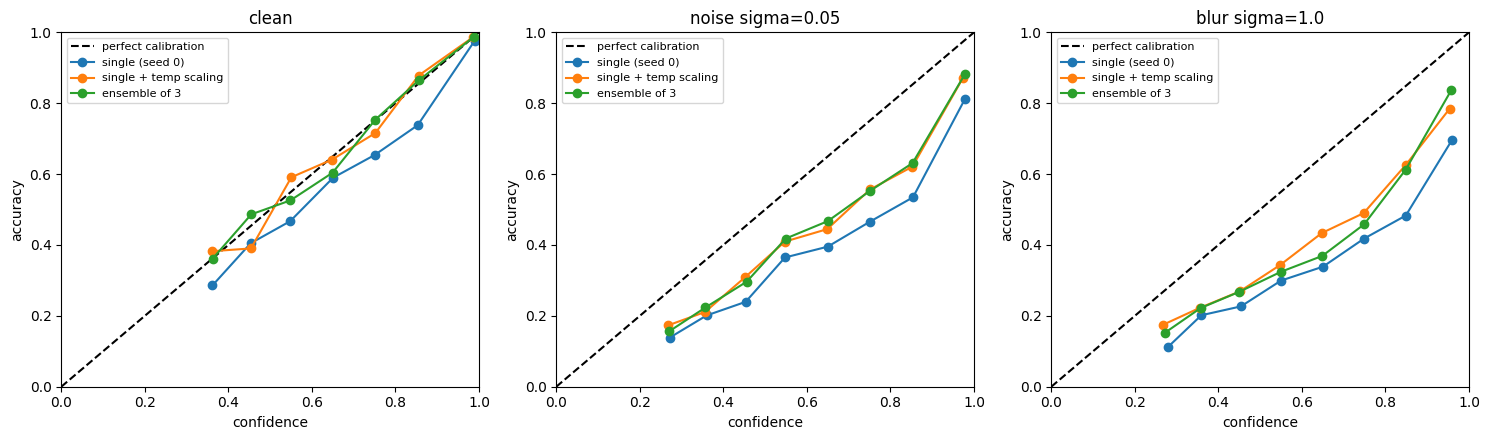

In [ ]:
import matplotlib.pyplot as plt

def reliability(p, y, n_bins=10):
    conf, pred = p.max(1)
    correct = (pred == y).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() >= 20:
            xs.append(conf[mask].mean().item()); ys.append(correct[mask].mean().item())
    return xs, ys

def probs_for(Xs):
    ls = [logits_of(m, Xs) for m in members]
    return {"single (seed 0)": F.softmax(ls[0], 1),
            "single + temp scaling": F.softmax(ls[0] / temps[0], 1),
            "ensemble of 3": torch.stack([F.softmax(l, 1) for l in ls]).mean(0)}

conds = {"clean": Xb, "noise sigma=0.05": add_noise(Xb, 0.05), "blur sigma=1.0": blur(Xb, 1.0)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (title, Xs) in zip(axes, conds.items()):
    ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
    for name, p in probs_for(Xs).items():
        xs, ys = reliability(p, yb)
        ax.plot(xs, ys, marker="o", label=name)
    ax.set_title(title); ax.set_xlabel("confidence"); ax.set_ylabel("accuracy")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("reliability.png", dpi=150)
plt.show()

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
CKPT = "/content/drive/MyDrive/cifar_v2"
os.makedirs(CKPT, exist_ok=True)

if os.path.exists("/content/drive/MyDrive/cifar_data") and not os.path.exists("./data"):
    shutil.copytree("/content/drive/MyDrive/cifar_data", "./data")
    print("restored dataset from Drive")

mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(mean, std)])
test_tf = T.Compose([T.ToTensor(), T.Normalize(mean, std)])

full_train = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=train_tf)
full_train_eval = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=test_tf)
test_set = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)

g = torch.Generator().manual_seed(1234)
perm = torch.randperm(50000, generator=g).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]
train_loader = DataLoader(Subset(full_train, train_idx), batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(Subset(full_train_eval, val_idx), batch_size=256, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)
print("train / val / test:", len(train_idx), len(val_idx), len(test_set))

class SmallCNN(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 64), block(64, 128), block(128, 256))
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(256 * 4 * 4, 10)
    def forward(self, x):
        x = self.features(x).flatten(1)
        return self.fc(self.drop(x))

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def evaluate(model, loader):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item(); total += y.size(0)
    return correct / total

def train(model, epochs=15, lr=0.05, aug_fn=None):
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4, nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs,
                                                steps_per_epoch=len(train_loader))
    for ep in range(epochs):
        model.train(); running = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if aug_fn is not None:
                x = aug_fn(x)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step(); sched.step()
            running += loss.item()
        print(f"  epoch {ep+1}: loss {running/len(train_loader):.3f}, val acc {evaluate(model, val_loader):.3f}")

def get_model(tag, seed, aug_fn=None):
    path = f"{CKPT}/{tag}_seed{seed}.pt"
    if os.path.exists(path):
        model = SmallCNN().to(device)
        model.load_state_dict(torch.load(path, map_location=device))
        print(f"loaded {tag} seed {seed}")
    else:
        set_seed(seed)
        model = SmallCNN().to(device)
        print(f"training {tag} seed {seed}")
        train(model, aug_fn=aug_fn)
        torch.save(model.state_dict(), path)
    model.eval()
    return model

std_models = [get_model("std", s) for s in range(5)]
for s, m in enumerate(std_models):
    print(f"std seed {s}: val acc {evaluate(m, val_loader):.3f} | test acc {evaluate(m, test_loader):.3f}")

Mounted at /content/drive
device: cuda
restored dataset from Drive
train / val / test: 45000 5000 10000
loaded std seed 0
training std seed 1
  epoch 1: loss 1.475, val acc 0.617
  epoch 2: loss 1.037, val acc 0.651
  epoch 3: loss 0.829, val acc 0.689
  epoch 4: loss 0.705, val acc 0.767
  epoch 5: loss 0.613, val acc 0.775
  epoch 6: loss 0.547, val acc 0.808
  epoch 7: loss 0.498, val acc 0.810
  epoch 8: loss 0.453, val acc 0.834
  epoch 9: loss 0.415, val acc 0.832
  epoch 10: loss 0.381, val acc 0.855
  epoch 11: loss 0.339, val acc 0.867
  epoch 12: loss 0.301, val acc 0.887
  epoch 13: loss 0.248, val acc 0.889
  epoch 14: loss 0.208, val acc 0.902
  epoch 15: loss 0.177, val acc 0.902
training std seed 2
  epoch 1: loss 1.454, val acc 0.552
  epoch 2: loss 1.008, val acc 0.665
  epoch 3: loss 0.820, val acc 0.754
  epoch 4: loss 0.699, val acc 0.713
  epoch 5: loss 0.613, val acc 0.749
  epoch 6: loss 0.546, val acc 0.797
  epoch 7: loss 0.499, val acc 0.805
  epoch 8: loss 0.

In [3]:
import json

val_y = torch.tensor([full_train_eval.targets[i] for i in val_idx])
test_y = torch.tensor(test_set.targets)

def probs_of(model, loader, mode="plain", passes=20):
    model.eval()
    if mode == "mc":
        model.drop.train()          # only dropout stays random; BatchNorm stays in eval mode
    outs = []
    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device)
            if mode == "plain":
                p = F.softmax(model(x), 1)
            elif mode == "flip":
                p = (F.softmax(model(x), 1) + F.softmax(model(x.flip(3)), 1)) / 2
            else:
                p = torch.stack([F.softmax(model(x), 1) for _ in range(passes)]).mean(0)
            outs.append(p.cpu())
    model.eval()
    return torch.cat(outs)

def ece_score(p, y, bins=15):
    conf, pred = p.max(1)
    correct = (pred == y).float()
    edges = torch.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.float().mean() * (correct[m].mean() - conf[m].mean()).abs()
    return float(e)

def nll_score(p, y):
    return float(-torch.log(p[torch.arange(len(y)), y].clamp_min(1e-12)).mean())

def metrics(p, y):
    return dict(acc=float((p.argmax(1) == y).float().mean()),
                conf=float(p.max(1)[0].mean()),
                ece=ece_score(p, y), nll=nll_score(p, y))

def apply_T(p, Tm):
    return F.softmax(torch.log(p.clamp_min(1e-12)) / Tm, 1)

def fit_T(p_val, y_val):
    best_nll, best_T = 1e9, 1.0
    for Tm in torch.arange(0.5, 3.01, 0.05):
        n = nll_score(apply_T(p_val, float(Tm)), y_val)
        if n < best_nll:
            best_nll, best_T = n, float(Tm)
    return best_T

torch.manual_seed(0)
rows, temps, plain_val, plain_test = {}, {}, [], []

for mode, label in [("plain", "single"), ("mc", "MC dropout"), ("flip", "flip TTA")]:
    for model in std_models:
        pv = probs_of(model, val_loader, mode)
        pt = probs_of(model, test_loader, mode)
        if mode == "plain":
            plain_val.append(pv); plain_test.append(pt)
        Tm = fit_T(pv, val_y)
        rows.setdefault(label, []).append(metrics(pt, test_y))
        rows.setdefault(label + " + temp", []).append(metrics(apply_T(pt, Tm), test_y))
        temps.setdefault(label, []).append(Tm)

ev, et = torch.stack(plain_val).mean(0), torch.stack(plain_test).mean(0)
Te = fit_T(ev, val_y)
rows["ensemble (5)"] = [metrics(et, test_y)]
rows["ensemble (5) + temp"] = [metrics(apply_T(et, Te), test_y)]
temps["ensemble"] = [Te]

print(f"{'method':<24}{'acc':>14}{'conf':>14}{'ECE':>16}{'NLL':>16}")
for name, ms in rows.items():
    def f(k):
        v = torch.tensor([m[k] for m in ms])
        return f"{v.mean():.3f}±{v.std():.3f}" if len(ms) > 1 else f"{v.mean():.3f}"
    print(f"{name:<24}{f('acc'):>14}{f('conf'):>14}{f('ece'):>16}{f('nll'):>16}")
print("fitted temperatures:", {k: [round(t, 2) for t in v] for k, v in temps.items()})

json.dump({"rows": rows, "temps": temps}, open(f"{CKPT}/stage2_results.json", "w"))
print("saved results to Drive")

method                             acc          conf             ECE             NLL
single                     0.899±0.003   0.927±0.001     0.029±0.003     0.312±0.006
single + temp              0.899±0.003   0.898±0.002     0.007±0.001     0.296±0.006
MC dropout                 0.898±0.003   0.919±0.001     0.022±0.002     0.305±0.006
MC dropout + temp          0.898±0.003   0.896±0.002     0.007±0.001     0.296±0.006
flip TTA                   0.903±0.002   0.919±0.002     0.016±0.002     0.287±0.006
flip TTA + temp            0.903±0.002   0.900±0.003     0.006±0.002     0.281±0.006
ensemble (5)                     0.912         0.912           0.008           0.257
ensemble (5) + temp              0.912         0.907           0.008           0.257
fitted temperatures: {'single': [1.35, 1.35, 1.3, 1.35, 1.3], 'MC dropout': [1.25, 1.25, 1.25, 1.25, 1.25], 'flip TTA': [1.2, 1.25, 1.2, 1.2, 1.2], 'ensemble': [1.05]}
saved results to Drive


In [6]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, Subset

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
CKPT = "/content/drive/MyDrive/cifar_v2"
os.makedirs(CKPT, exist_ok=True)

if os.path.exists("/content/drive/MyDrive/cifar_data") and not os.path.exists("./data"):
    shutil.copytree("/content/drive/MyDrive/cifar_data", "./data")
    print("restored dataset from Drive")

mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(mean, std)])
test_tf = T.Compose([T.ToTensor(), T.Normalize(mean, std)])

full_train = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=train_tf)
full_train_eval = torchvision.datasets.CIFAR10("./data", train=True, download=False, transform=test_tf)
test_set = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)

g = torch.Generator().manual_seed(1234)
perm = torch.randperm(50000, generator=g).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]
train_loader = DataLoader(Subset(full_train, train_idx), batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(Subset(full_train_eval, val_idx), batch_size=256, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=2)
print("train / val / test:", len(train_idx), len(val_idx), len(test_set))

class SmallCNN(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        def block(i, o):
            return nn.Sequential(
                nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 64), block(64, 128), block(128, 256))
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(256 * 4 * 4, 10)
    def forward(self, x):
        x = self.features(x).flatten(1)
        return self.fc(self.drop(x))

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def evaluate(model, loader):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += (model(x).argmax(1) == y).sum().item(); total += y.size(0)
    return correct / total

def train(model, epochs=15, lr=0.05, aug_fn=None):
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4, nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs,
                                                steps_per_epoch=len(train_loader))
    for ep in range(epochs):
        model.train(); running = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            if aug_fn is not None:
                x = aug_fn(x)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step(); sched.step()
            running += loss.item()
        print(f"  epoch {ep+1}: loss {running/len(train_loader):.3f}, val acc {evaluate(model, val_loader):.3f}")

def get_model(tag, seed, aug_fn=None):
    path = f"{CKPT}/{tag}_seed{seed}.pt"
    if os.path.exists(path):
        model = SmallCNN().to(device)
        model.load_state_dict(torch.load(path, map_location=device))
        print(f"loaded {tag} seed {seed}")
    else:
        set_seed(seed)
        model = SmallCNN().to(device)
        print(f"training {tag} seed {seed}")
        train(model, aug_fn=aug_fn)
        torch.save(model.state_dict(), path)
    model.eval()
    return model

std_models = [get_model("std", s) for s in range(5)]
for s, m in enumerate(std_models):
    print(f"std seed {s}: val acc {evaluate(m, val_loader):.3f} | test acc {evaluate(m, test_loader):.3f}")

Mounted at /content/drive
device: cuda
restored dataset from Drive
train / val / test: 45000 5000 10000
loaded std seed 0
loaded std seed 1
loaded std seed 2
loaded std seed 3
loaded std seed 4
std seed 0: val acc 0.900 | test acc 0.902
std seed 1: val acc 0.902 | test acc 0.894
std seed 2: val acc 0.901 | test acc 0.897
std seed 3: val acc 0.899 | test acc 0.900
std seed 4: val acc 0.896 | test acc 0.900


In [7]:
val_y = torch.tensor([full_train_eval.targets[i] for i in val_idx])
test_y = torch.tensor(test_set.targets)

def ece_score(p, y, bins=15):
    conf, pred = p.max(1)
    correct = (pred == y).float()
    edges = torch.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.float().mean() * (correct[m].mean() - conf[m].mean()).abs()
    return float(e)

def nll_score(p, y):
    return float(-torch.log(p[torch.arange(len(y)), y].clamp_min(1e-12)).mean())

def metrics(p, y):
    return dict(acc=float((p.argmax(1) == y).float().mean()),
                conf=float(p.max(1)[0].mean()),
                ece=ece_score(p, y), nll=nll_score(p, y))

def apply_T(p, Tm):
    return F.softmax(torch.log(p.clamp_min(1e-12)) / Tm, 1)

def fit_T(p_val, y_val):
    best_nll, best_T = 1e9, 1.0
    for Tm in torch.arange(0.5, 3.01, 0.05):
        n = nll_score(apply_T(p_val, float(Tm)), y_val)
        if n < best_nll:
            best_nll, best_T = n, float(Tm)
    return best_T

In [8]:
import torchvision.transforms.functional as TF

mean_t = torch.tensor(mean, device=device).view(1, 3, 1, 1)
std_t = torch.tensor(std, device=device).view(1, 3, 1, 1)
def to_pix(x): return x * std_t + mean_t
def to_norm(x): return (x - mean_t) / std_t

def add_noise(x, sigma):
    p = to_pix(x)
    return to_norm((p + torch.randn_like(p) * sigma).clamp(0, 1))

def blur(x, sigma):
    p = to_pix(x)
    return to_norm(TF.gaussian_blur(p, kernel_size=5, sigma=sigma).clamp(0, 1))

def noise_blur_aug(x):
    pick = torch.rand(x.size(0), device=device)
    out = x.clone()
    noise_m = pick < 0.25
    blur_m = (pick >= 0.25) & (pick < 0.5)
    if noise_m.any():
        s = torch.rand(int(noise_m.sum()), 1, 1, 1, device=device) * 0.23 + 0.02
        out[noise_m] = add_noise(x[noise_m], s)
    if blur_m.any():
        out[blur_m] = blur(x[blur_m], float(torch.empty(1).uniform_(0.5, 1.6)))
    return out

aug_models = [get_model("aug", s, aug_fn=noise_blur_aug) for s in range(5)]
for s, m in enumerate(aug_models):
    print(f"aug seed {s}: val acc {evaluate(m, val_loader):.3f} | test acc {evaluate(m, test_loader):.3f}")

training aug seed 0
  epoch 1: loss 1.604, val acc 0.538
  epoch 2: loss 1.223, val acc 0.618
  epoch 3: loss 1.030, val acc 0.672
  epoch 4: loss 0.908, val acc 0.735
  epoch 5: loss 0.831, val acc 0.741
  epoch 6: loss 0.776, val acc 0.736
  epoch 7: loss 0.724, val acc 0.752
  epoch 8: loss 0.676, val acc 0.801
  epoch 9: loss 0.634, val acc 0.799
  epoch 10: loss 0.597, val acc 0.812
  epoch 11: loss 0.565, val acc 0.835
  epoch 12: loss 0.519, val acc 0.837
  epoch 13: loss 0.471, val acc 0.850
  epoch 14: loss 0.422, val acc 0.867
  epoch 15: loss 0.392, val acc 0.870
training aug seed 1
  epoch 1: loss 1.624, val acc 0.527
  epoch 2: loss 1.257, val acc 0.609
  epoch 3: loss 1.045, val acc 0.701
  epoch 4: loss 0.920, val acc 0.693
  epoch 5: loss 0.836, val acc 0.733
  epoch 6: loss 0.773, val acc 0.765
  epoch 7: loss 0.718, val acc 0.768
  epoch 8: loss 0.670, val acc 0.760
  epoch 9: loss 0.640, val acc 0.819
  epoch 10: loss 0.594, val acc 0.817
  epoch 11: loss 0.558, val 

In [9]:
import json
X_test = torch.cat([x for x, _ in test_loader]).to(device)
X_val = torch.cat([x for x, _ in val_loader]).to(device)

def probs_X(model, X):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), 1000):
            out.append(F.softmax(model(X[i:i + 1000]), 1).cpu())
    return torch.cat(out)

def contrast(x, f):
    p = to_pix(x); m = p.mean(dim=(1, 2, 3), keepdim=True)
    return to_norm(((p - m) * f + m).clamp(0, 1))
def brightness(x, d):
    return to_norm((to_pix(x) + d).clamp(0, 1))

conds = [("clean", lambda x: x),
         ("noise 0.05", lambda x: add_noise(x, 0.05)),
         ("noise 0.1", lambda x: add_noise(x, 0.1)),
         ("noise 0.2", lambda x: add_noise(x, 0.2)),
         ("blur 0.7", lambda x: blur(x, 0.7)),
         ("blur 1.0", lambda x: blur(x, 1.0)),
         ("blur 1.5", lambda x: blur(x, 1.5)),
         ("contrast 0.5 (unseen)", lambda x: contrast(x, 0.5)),
         ("contrast 0.3 (unseen)", lambda x: contrast(x, 0.3)),
         ("contrast 0.15 (unseen)", lambda x: contrast(x, 0.15)),
         ("brightness +0.3 (unseen)", lambda x: brightness(x, 0.3))]

groups = {"std": std_models, "aug": aug_models}
Ts, Te = {}, {}
for tag, models in groups.items():
    pvs = [probs_X(m, X_val) for m in models]
    Ts[tag] = [fit_T(pv, val_y) for pv in pvs]
    Te[tag] = fit_T(torch.stack(pvs).mean(0), val_y)
print("temps:", {k: [round(t, 2) for t in v] for k, v in Ts.items()}, {k: round(v, 2) for k, v in Te.items()})

res = {}
for cname, fn in conds:
    torch.manual_seed(123)
    Xc = fn(X_test)
    for tag, models in groups.items():
        P = [probs_X(m, Xc) for m in models]
        single = [metrics(apply_T(p, t), test_y) for p, t in zip(P, Ts[tag])]
        ens = metrics(apply_T(torch.stack(P).mean(0), Te[tag]), test_y)
        res[(cname, tag)] = (single, ens)

def avg(ms, k): return sum(m[k] for m in ms) / len(ms)
print(f"{'condition (acc / ECE)':<26}{'std single':>16}{'aug single':>16}{'std ens':>16}{'aug ens':>16}")
for cname, _ in conds:
    cells = []
    for tag in ["std", "aug"]:
        s, _e = res[(cname, tag)]
        cells.append(f"{avg(s,'acc'):.3f} / {avg(s,'ece'):.3f}")
    for tag in ["std", "aug"]:
        _s, e = res[(cname, tag)]
        cells.append(f"{e['acc']:.3f} / {e['ece']:.3f}")
    print(f"{cname:<26}{cells[0]:>16}{cells[1]:>16}{cells[2]:>16}{cells[3]:>16}")

json.dump({f"{c}|{t}": v for (c, t), v in res.items()}, open(f"{CKPT}/stage3_results.json", "w"))
print("saved")

temps: {'std': [1.35, 1.35, 1.3, 1.35, 1.3], 'aug': [1.25, 1.25, 1.3, 1.25, 1.25]} {'std': 1.05, 'aug': 1.05}
condition (acc / ECE)           std single      aug single         std ens         aug ens
clean                        0.899 / 0.007   0.871 / 0.007   0.912 / 0.008   0.882 / 0.006
noise 0.05                   0.646 / 0.126   0.857 / 0.010   0.669 / 0.104   0.870 / 0.012
noise 0.1                    0.305 / 0.386   0.826 / 0.016   0.307 / 0.381   0.846 / 0.021
noise 0.2                    0.138 / 0.536   0.730 / 0.022   0.119 / 0.578   0.759 / 0.035
blur 0.7                     0.704 / 0.045   0.855 / 0.014   0.725 / 0.041   0.867 / 0.013
blur 1.0                     0.406 / 0.209   0.832 / 0.016   0.419 / 0.227   0.849 / 0.017
blur 1.5                     0.277 / 0.291   0.793 / 0.016   0.285 / 0.326   0.809 / 0.014
contrast 0.5 (unseen)        0.835 / 0.013   0.824 / 0.011   0.851 / 0.012   0.838 / 0.011
contrast 0.3 (unseen)        0.599 / 0.037   0.700 / 0.016   0.626 / 0.

In [11]:
import os
from sklearn.metrics import roc_auc_score

X_test = torch.cat([x for x, _ in test_loader]).to(device)

try:
    svhn = torchvision.datasets.SVHN("./data", split="test", download=True, transform=test_tf)
    svhn_loader = DataLoader(Subset(svhn, range(10000)), batch_size=256, shuffle=False, num_workers=2)
    X_ood = torch.cat([x for x, _ in svhn_loader]).to(device)
    print("loaded SVHN via torchvision")
except Exception as e:
    print("torchvision download failed:", type(e).__name__, "- using Hugging Face mirror")
    os.system("pip -q install datasets")
    from datasets import load_dataset
    ds = load_dataset("ufldl-stanford/svhn", "cropped_digits", split="test[:10000]")
    X_ood = torch.stack([test_tf(img.convert("RGB")) for img in ds["image"]]).to(device)
    print("loaded SVHN via Hugging Face")
print("OOD set:", tuple(X_ood.shape))

def probs_X(model, X):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), 1000):
            out.append(F.softmax(model(X[i:i + 1000]), 1).cpu())
    return torch.cat(out)

def auroc(p_in, p_out):
    s = torch.cat([p_in.max(1)[0], p_out.max(1)[0]]).numpy()
    lab = np.concatenate([np.ones(len(p_in)), np.zeros(len(p_out))])
    return roc_auc_score(lab, s)

print(f"{'method':<22}{'AUROC':>14}{'conf CIFAR':>14}{'conf SVHN':>14}")
for tag, models in [("std", std_models), ("aug", aug_models)]:
    Pin = [probs_X(m, X_test) for m in models]
    Pout = [probs_X(m, X_ood) for m in models]
    a = torch.tensor([auroc(i, o) for i, o in zip(Pin, Pout)])
    ci = torch.tensor([i.max(1)[0].mean() for i in Pin])
    co = torch.tensor([o.max(1)[0].mean() for o in Pout])
    print(f"{tag + ' single':<22}{f'{a.mean():.3f}±{a.std():.3f}':>14}{f'{ci.mean():.3f}':>14}{f'{co.mean():.3f}':>14}")
    ei, eo = torch.stack(Pin).mean(0), torch.stack(Pout).mean(0)
    print(f"{tag + ' ensemble':<22}{auroc(ei, eo):>14.3f}{ei.max(1)[0].mean():>14.3f}{eo.max(1)[0].mean():>14.3f}")

torchvision download failed: URLError - using Hugging Face mirror


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

cropped_digits/train-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  136MB            

cropped_digits/train-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

cropped_digits/test-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 47.0MB            

...

cropped_digits/extra-00001-of-00002.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/73257 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/26032 [00:00<?, ? examples/s]

Generating extra split:   0%|          | 0/531131 [00:00<?, ? examples/s]

loaded SVHN via Hugging Face
OOD set: (10000, 3, 32, 32)
method                         AUROC    conf CIFAR     conf SVHN
std single               0.926±0.010         0.927         0.600
std ensemble                   0.925         0.912         0.567
aug single               0.899±0.003         0.898         0.570
aug ensemble                   0.907         0.885         0.532


In [4]:
import torch
print(torch.cuda.is_available())

True
